<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EC%8B%AC%EC%B8%B5%EC%8B%A0%EA%B2%BD%EB%A7%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

여러 계층(layer)가 쌓여서 만들어진 합성 함수입니다.

심층신경망이 깊어질수록 활성함수의 미분 계수가 전 구간에서 1보다 작아져 학습의 속도가 점점 더뎌지는 문제가 발생합니다.

이처럼 깊어지는 심층신경망에서 입력에 가까운 계층이 잘 학습되지 않는 문제를 **그래디언트 소실**이라고 부릅니다.

그래디언트 소실 문제를 해결하기 위해 심층신경망에는 활성화 함수로 렐루(ReLu)를 사용합니다.

음수 구간에서는 전부 0의 값을 지니게 되며 양수 구간에서는 전부 기울기가 1인 형태가 됩니다. 양수 구간에서의 기울기가 1인 덕분에 렐루를 통해 구현된 심층신경망은 매우 빠른 최적화가 가능합니다.

(렐루를 사용해도 여전히 음수 구간은 기울기가 0보다 작기 때문에 그래디언트 소실 문제가 완전히 해결된 것은 아닙니다. ResNet의 skip-connection을 통해 그래디언트 소실을 완벽하게 해결할 수 있습니다.)

- 심층신경망
  - 선형 회귀 또는 로지스틱 회귀는 비선형 문제는 풀 수 없습니다.
  - 션형 계층들 사이에 비선형 함수를 넣어 비선형 함수로 만들 수 있습니다.
  - 선형 계층과 비선형 활성 함수를 반복해서 쌓아 심층신경망을 구성할 수 있습니다.
  - 신경망의 깊이와 너비는 하이퍼 파라미터로 깊이가 깊고 너비가 넓을수록 복잡한 함수를 배울 수 있는 수용 능력이 높아집니다.

- 역전파 알고리즘
  - 역전파 알고리즘은 체인 룰을 활용하여 복잡한 수식의 미분을 작게 분리하여 효율적으로 계산 및 계산 결과를 재활용할 수 있게 합니다.

- 그래디언트 소실
  - sigmoid()와 tanh()의 기울기 값은 전 영역에서 1 이하입니다.
  - 따라서 sigmoid()와 tanh()가 반복 사용될수록 신경망의 입력 쪽 계층 가중치 파라미터의 그래디언트는 작아집니다.
  - 너무 그래디언트가 작아지게 되면 가중치 파라미터 업데이트를 거의 할 수 없으므로, 학습이 진행되지 않습니다.

- ReLU
  - 그래디언트 소실 문제를 어느 정도 해결할 수 있습니다.
  - LeakyReLU는 음의 영역에 기울기가 존재하지만, ReLU와 딱히 성능 상에 우열을 가리기 어렵습니다.
  - ReLU(x)=max(0,x)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.datasets import fetch_california_housing
house=fetch_california_housing()

df=pd.DataFrame(data=house.data,columns=house.feature_names)
df['target']=house.target

df.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


최적화 및 성능 향상을 위해 표준 스케일링을 통해 입력 값을 정규화하도록 하겠습니다.

정규화를 적용하기 전에 데이터셋 분포의 특징을 파악하고 어떤 정규화 방법이 가장 어울릴지 결정해야 합니다.

In [9]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df.iloc[:,:-1]=scaler.fit_transform(df.iloc[:,:-1]).round(4)

df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,2.3448,0.9821,0.6286,-0.1538,-0.9744,-0.0496,1.0525,-1.3278,4.526
1,2.3322,-0.6070,0.3270,-0.2633,0.8614,-0.0925,1.0432,-1.3228,3.585
2,1.7827,1.8562,1.1556,-0.0490,-0.8208,-0.0258,1.0385,-1.3328,3.521
3,0.9330,1.8562,0.1570,-0.0498,-0.7660,-0.0503,1.0385,-1.3378,3.413
4,-0.0129,1.8562,0.3447,-0.0329,-0.7598,-0.0856,1.0385,-1.3378,3.422


In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

In [11]:
data = torch.from_numpy(df.values).float()

X = data[:,:-1]
y = data[:,-1:]

In [14]:
class MyModel(nn.Module):
  def __init__(self,input_dim,output_dim):
    self.input_dim=input_dim
    self.output_dim=output_dim

    super().__init__()

    self.linear1=nn.Linear(input_dim,3)
    self.linear2=nn.Linear(3,3)
    self.linear3=nn.Linear(3,3)
    self.linear4=nn.Linear(3,output_dim)
    self.act=nn.ReLU()

  def forward(self,x):
    #|h|=(batch_size,3)
    h1=self.act(self.linear1(x))
    h2=self.act(self.linear2(h1))
    h3=self.act(self.linear3(h2))

    # |y|=(batch_size,output_dim)
    y=self.act(self.linear4(h3))

    return y



In [16]:
model=MyModel(X.size(-1),y.size(-1))
print(model)

MyModel(
  (linear1): Linear(in_features=8, out_features=3, bias=True)
  (linear2): Linear(in_features=3, out_features=3, bias=True)
  (linear3): Linear(in_features=3, out_features=3, bias=True)
  (linear4): Linear(in_features=3, out_features=1, bias=True)
  (act): ReLU()
)


nn.Sequntial 클래스 사용하기

In [17]:
model=nn.Sequential(
    nn.Linear(X.size(-1),3),
    nn.LeakyReLU(),
    nn.Linear(3,3),
    nn.LeakyReLU(),
    nn.Linear(3,3),
    nn.LeakyReLU(),
    nn.Linear(3,y.size(-1))
)
print(model)

Sequential(
  (0): Linear(in_features=8, out_features=3, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=3, out_features=3, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=3, out_features=3, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=3, out_features=1, bias=True)
)


In [19]:
n_epochs=200000
learning_rate=1e-3
print_interval=10000

In [20]:
optimizer=optim.SGD(model.parameters(),lr=learning_rate)
print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [21]:
for i in tqdm(range(n_epochs)):
  y_hat=model(X)
  loss=F.mse_loss(y_hat,y)

  optimizer.zero_grad()
  loss.backward()

  optimizer.step()

  if (i+1) % print_interval == 0:
    print('Epoch %d: loss=%.4e' % (i + 1,loss))

  5%|▌         | 10049/200000 [00:34<10:38, 297.31it/s]

Epoch 10000: loss=4.9216e-01


 10%|█         | 20038/200000 [01:09<09:50, 304.92it/s]

Epoch 20000: loss=4.3810e-01


 15%|█▌        | 30035/200000 [01:42<09:04, 312.36it/s]

Epoch 30000: loss=4.0620e-01


... (30 outputs left out)

 95%|█████████▌| 190035/200000 [11:01<00:33, 293.48it/s]

Epoch 190000: loss=3.5501e-01


100%|██████████| 200000/200000 [11:36<00:00, 287.16it/s]

Epoch 200000: loss=3.5379e-01


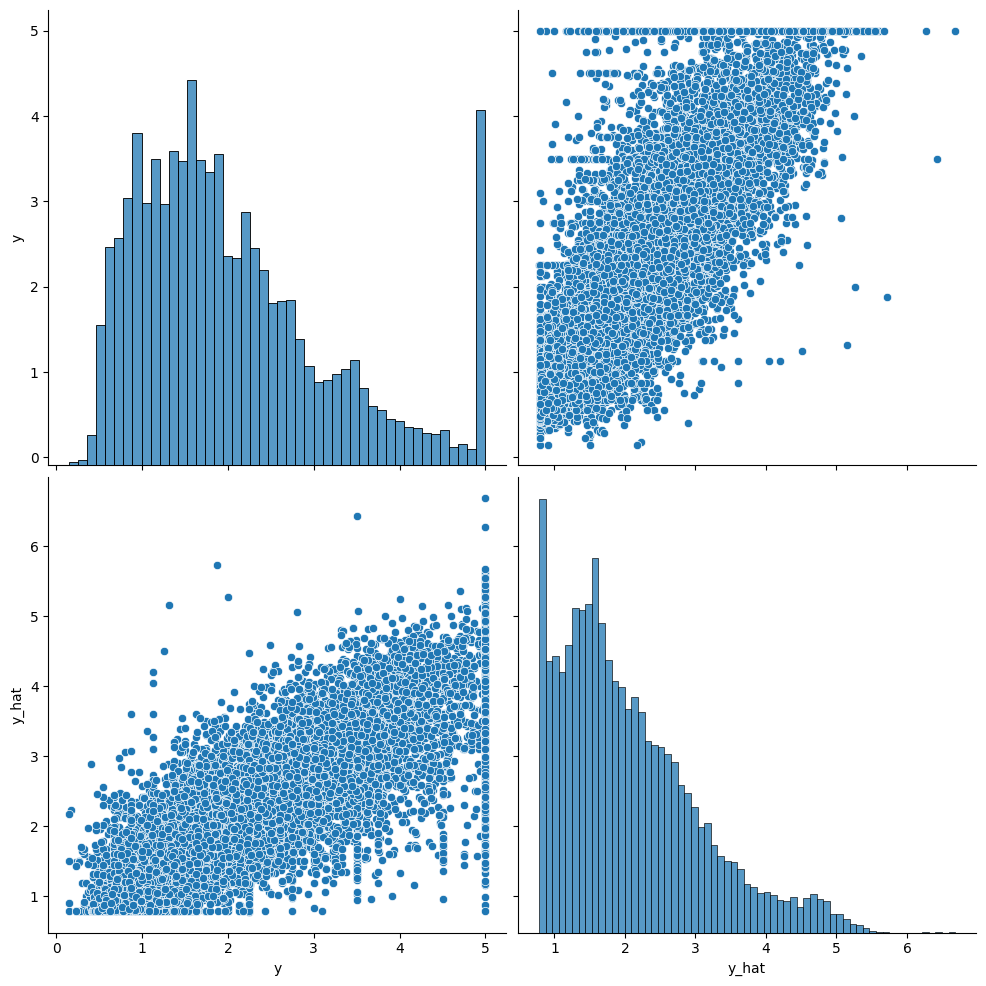

In [22]:
# 시각화
df=pd.DataFrame(torch.cat([y,y_hat],dim=1).detach().numpy(),
                columns=['y','y_hat'])

sns.pairplot(df,height=5)
plt.show()